<a href="https://colab.research.google.com/github/Insight-Sogang-Univ/insight-16th/blob/hyewon/advanced/hyewon/session01/%ED%8D%BC%EC%85%89%ED%8A%B8%EB%A1%A0_%EC%82%AC%EC%A0%84%EA%B3%BC%EC%A0%9C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 인공신경망
>우리 뇌의 신경망(뇌를 구성하는 신경세포끼리 연결되어 정보를 처리하는 구조)를 모방한 모델

$$\sum x_i w_i + b$$

- 입력을 받아 각각 가중치와 편향을 적용
- 종합한 값을 활성화 함수에 넘김 (기준 미달이면 0에 가깝게, 기준 통화면 유의미한 값으로 보냄)
- 아웃풋 출력

# 퍼셉트론
>초기 형태의 인공신경망으로 딥러닝의 기원이 되는 선형 이진분류기

$$net = \sum_{i}^{N} x_i w_i$$

**[순서] 입력->가중합->활성화함수->출력**
- 입력값과 가중치를 곱함
- 곱한 값들의 총합을 구함 (편향은 옵션)
- 총합이 임계값을 넘으면 1, 안넘으면 0 출력 (이 여부에 따라 활성화함수가 출력값 결정)


# 단층 퍼셉트론과 그 한계

## 단층퍼셉트론
> 단순 `입력층`과 `출력층`으로만 이루어진 퍼셉트론.

값을 보내는 단계와 받아서 출력하는 단계로만 이루어짐

## 논리게이트 구현
> 논리게이트란 디지털 회로에서 기분적인 논리연산을 수행하는데 사용되는 구성요소로 AND, OR, NOT, NAND, NOR, XOR 등 다양한 종류가 있음

## 단층 퍼셉트론의 한계
**!XOR게이트를 구현할 수 없음!**

퍼셉트론은 입력값과 가중치의 선형 결합으로 이루어진 구조기 때문에 단층 퍼셉트론은 직선 하나로 두 영역을 나눌 수 있는 선형분류 문제에만 구현 가능

=> *XOR게이트는 직선이 아닌 곡선/비선형 영역으로 분리해야만 구현 가능*

# 다층퍼셉트론
> 단층+은닉층

- XOR게이트는 기존의 AND, NAND, OR게이트를 조합해 만들 수 있다!

- 단순히 층을 많이 쌓는 것이 아니라, 은닉층에서 비선형 활성화 함수를 적용해 새로운 특징을 만들고 그 다음 층에서 그 특징들을 조합해서 구현이 가능하다

- 예시: 은닉층의 두 뉴런이 각각 NAND와 OR을 계산하고, 출력층이 두 결과에 AND를 적용하면 XOR이 됨

- 각 게이트는 비선형 계단 함수 사용

$$
\begin{aligned}
h &= \sigma(W_1x + b_1) \\
y &= W_2h + b_2
\end{aligned}
$$

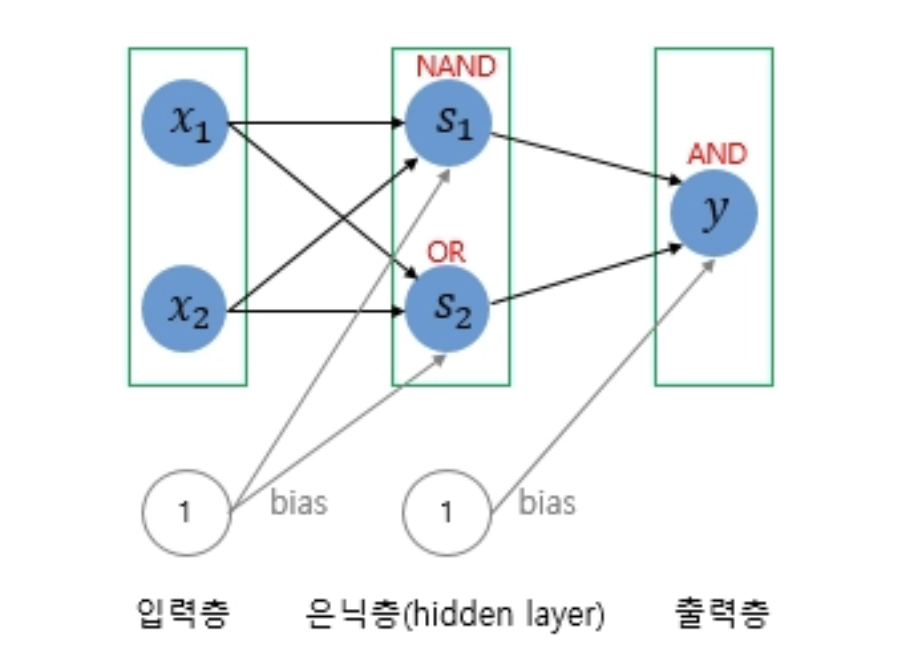

더 복잡한 문제를 해결할 때에는 중간에 수많은 은닉층을 추가할 수 있다
- 심층신경망: 은닉층이 2개 이상인 심층신경망
- 딥러닝: 심층신경망을 학습시킨 것

# 딥러닝 모델은 어떻게 학습?

**1. 순전파를 통해 입력값으로부터 예측**
  - 입력값이 각 층을 통과하면 예측값 나옴

**2. 오차 계산을 통해 예측 정확도 측정**
  - 예측값과 실제 정답을 비교해서 오차, 손실을 계산

**3. 역전파를 통해 출력층에서 다시 입력층 방향으로 오차 전달**
  - 각 가중치가 손실에 얼마나 기여했는지,,, 따라서 가중치 w1은 손실에 직접적이지 않고 간접적이게 연결되어 있음

**4. 가중치 업데이트**
  - 가중치를 조금씩 수정해서 정확도를 높힌다.

**5. 윗 단계 반복**


=> 이 과정의 반복으로 오차값이 0에 가까워짐

### 순전파&역전파
  - 예측해보고(순전파), 틀린만큼 고치기(역전파)
  - 이 순전파와 역전파는 연쇄법칙을 통해 발생

### 연쇄법칙
> 오차를 줄이기 위해 역전파 과정에서 각 가중치가 최종 손실에 얼마나 기여했는지 계산하기 위해 사용
- 손실함수가 예측값과 실제값 차이를 수치로 표현

### 기울기 소실 문제
- 기울기들을 계속 곱하면 결국 기울기가 0이 되기 때문에, 앞쪽 층의 가중치가 거의 반영되지 않는 문제 발생








# 손실함수

> 모델의 예측이 얼마나 틀렸나(오차) 수치로 표현

주로 회귀에서는 평균제곱오차(MSE)를, 분류에서는 크로스 엔트로피 오차 사용

## 1. 평균제곱오차(MSE)

$$\frac{1}{N} \sum (y - \hat{y})^2$$

- `회귀`에서 적합
- 예측값이 연속적이고, 예측값과 실제값의 차이를 직접 측정하는데에 적합
- 단순 loss 크기만 봄


## 2. 이진 크로스 엔트로피(BCP)

$$L = -\left(y \log \hat{y} + (1 - y) \log(1 - \hat{y})\right)$$

- `이진분류 로지스틱 회귀`에서 사용하는데에 적합
- 실제 정답에 부여한 확률에 -log를 적용한 손실
- 단순 loss 크기 + 얼마나 확신을 가지고 예측했는지도 반영

## 3. 크로스 엔트로피(CEE)

$$-\sum y \log \hat{y}$$

- `다중 클래스 분류 문제`에서 적합







# 활성화 함수

- 활성화 함수를 거치는 이유
  - 비선형성이 필요하기 때문 for XOR
  - 미분이 되어야 하기 때문 for 역전파

## 1. 계단함수: 미분이 안돼서 역전파 X

$$h(x) = \begin{cases} 1 & (x \geq 0) \\ 0 & (x < 0) \end{cases}$$

- 주로 단층 퍼셉트론에서 사용
- 입력신호: 입력값*가중치
- 출력신호: 0 or 1
- 미분값이 0이라 역전파 x -> 다층퍼셉트롬 x

=> 가중치는 각 입력 신호가 결과에 미치는 영향력 제어

## 2. 시그모이드 함수: 미분 가능, 근데 기울기 소실 발생 문제
$$f(x)=\frac{1}{1+e^{-x}}$$

- 입력신호를 0과 1 사이의 연속적인 값으로 변환하는 비선형함수
- 출력값이 x값에 따라 연속적으로 변화하기에 얼마나 확실한지 표현가능하고 미분도 가능!
- 그러나 미분값이 최대가 0.25라서 기울기소실 문제 발생

## 3. ReLU: 곱해도 기울기 소실 x => Best!!

$$f(x)=\max(0,x)$$

- 입력이 0보다 크면 그대로, 0이하면 0을 출력
- 계산이 간단하고 효율적이라 많이 씀
- 음수는 0으로, 양수는 그대로 처리해서 은닉층에 비선형성 추가
- 양수구간에서 미분값이 항상 1이라서 아무리 곱해서 죽지 않아 기울기 소실이 완화되어  역전파가 안정적으로 전달됨.

## 4. Softmax 함수

$$ f(x_i)=\frac{e^{x_i}}{\sum_j e^{x_j}} $$

- 각 클래스에 대한 출력값을 확률로 변환
- 다중 클래스 분류문제의 출력층에서 사용





# 경사하강법

> 손실을 가장 작게 만드는 w를 찾는 것

- 미분값에 알파를 곱해서 이동량을 조절함
- 0.001부터 시작해야함. 학습률이 너무 작거나 커도 문제

1. 배치
  - 학습 과정에서 매개변수를 조정하기 위해 사용하는 데이터의 묶음
  - 배치크기가 너무 크면 학습이 느려지고, 너무 작으면 학습이 불안정

2. 에포크
  - 모든 데이터셋을 학습하는 횟수

3. 이터레이션
  - 한번의 에포크를 끝내기 위해 필요한 배치의 수
  - 배치크기 * 이터레이터 => 1에포크에서 다루는 데이터의 수


## 경사하강법의 종류
**1. 배치 경사하강법**
  - 오차를 구할 때 전체 데이터를 한 묶음으로 묶음
  - 전체데이터로 학습해서 업데이트 횟수 적지만 한번에 처리해서 메모리가 많이 필요함
  - 수렴이 안정적

**2. 확률적 경사하강법**
  - 위에 단점을 해결하기 위해 전체가 아닌 랜덤으로 선택된 하나의 데이터에 대해서만 계산
  - 그러나 매개변수의 변경폭이 불안정하고 정확도가 낮을 수 있음

**3. 미니배치 경사하강법**
  - 배치크기가 1이면 정확도가 낮고, 전체 배치는 메모리가 부족하다는 단점을 해결하기 위해 나온 방법
  - 배치크기를 적절히 지정해서 매개변수 조정
  - 전체 데이터보단 빠르고, 배치크기가 1보단 안정적이라 많이 사용됨




# 옵티마이저
> 딥러닝의 손실함수는 예쁜 볼록모양이 아님. 게다가 진짜 바닥이 아닌 작은 웅덩이도 기울기가 0이라 거기에 멈춰버리는 문제 발생

**1. 모멘텀**

*'이전에 가던 방향을 기억하도록 관성 부여'*

- 변수가 가던 방향으로 계속 가도록 속도 추가
- 이 방법을 통헤 작은 웅덩이를 탈출할 수 있다!

**2. 알엠에스프롭**

*'각 방향마다 학습률을 따로 조정해서 안정적이고 빠르게 학습하게 하자'*

- 최근 기울기를 참고해서
  1) 급한 경사에선 속도를 줄이고
  2) 완만한 경사에서는 솓도를 유지하거나 증가

**3. 아담**

*'위에 두 방법을 합쳐 방향과 학습률을 둘다 잡자'*

- 각 파라미터의 기울기의 평균과 기울기의 재곱쳥균을 이용해서 학습률 조정

